In [1]:
import pandas as pd

df = pd.read_csv("../data/marketing_campaign.csv", sep="\t")
print(df.shape)
df.head()

(2240, 29)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df.info()

Matplotlib is building the font cache; this may take a moment.


<class 'pandas.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   str    
 3   Marital_Status       2240 non-null   str    
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   str    
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   int64  
 16 

In [3]:
print(df.isna().sum()[lambda s: s > 0])
print("Doublons (sans ID) :", df.drop(columns="ID").duplicated().sum())

Income    24
dtype: int64
Doublons (sans ID) : 182


In [4]:
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], format="%d-%m-%Y")
print(df["Dt_Customer"].min(), df["Dt_Customer"].max())

constantes = [c for c in df.columns if df[c].nunique() == 1]
print("Colonnes constantes :", constantes)

2012-07-30 00:00:00 2014-06-29 00:00:00
Colonnes constantes : ['Z_CostContact', 'Z_Revenue']


In [5]:
print(df["Education"].value_counts(), "\n")
print(df["Marital_Status"].value_counts())

Education
Graduation    1127
PhD            486
Master         370
2n Cycle       203
Basic           54
Name: count, dtype: int64 

Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64


               Age         Income
count  2240.000000    2216.000000
mean     45.194196   52247.251354
std      11.984069   25173.076661
min      18.000000    1730.000000
25%      37.000000   35303.000000
50%      44.000000   51381.500000
75%      55.000000   68522.000000
max     121.000000  666666.000000


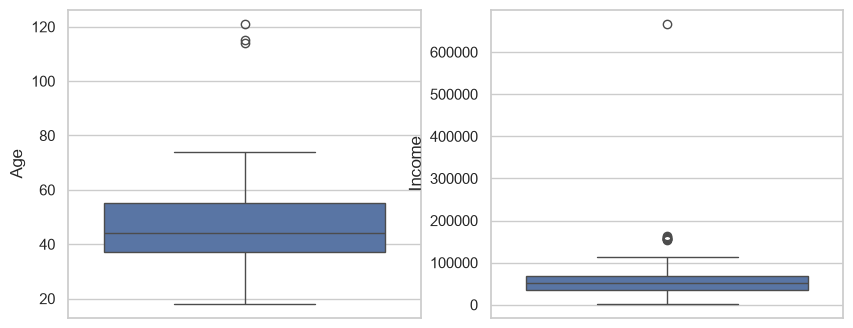

In [6]:
df["Age"] = 2014 - df["Year_Birth"]
print(df[["Age", "Income"]].describe())

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.boxplot(y=df["Age"], ax=ax[0])
sns.boxplot(y=df["Income"], ax=ax[1])
plt.show()

In [7]:
print("Avant :", df.shape)

# Colonnes constantes (inutiles)
df = df.drop(columns=["Z_CostContact", "Z_Revenue"])

# Âges impossibles
df = df[df["Age"] < 100]

# Outlier extrême de revenu (on garde les NaN pour l'imputation)
df = df[df["Income"].isna() | (df["Income"] < 200000)]

# Imputation du revenu par la médiane
df["Income"] = df["Income"].fillna(df["Income"].median())

# Regroupement de la situation familiale
df["Marital_Status"] = df["Marital_Status"].replace({
    "Alone": "Single", "Absurd": "Single", "YOLO": "Single",
    "Divorced": "Single", "Widow": "Single",
    "Married": "Couple", "Together": "Couple"
})

# Doublons (sans ID)
df = df.drop_duplicates(subset=df.columns.drop("ID"))

print("Après :", df.shape)
print(df["Marital_Status"].value_counts())
print(df.isna().sum().sum(), "valeurs manquantes restantes")


Avant : (2240, 30)
Après : (2051, 28)
Marital_Status
Couple    1314
Single     737
Name: count, dtype: int64
0 valeurs manquantes restantes


In [11]:
mnt_cols = [c for c in df.columns if c.startswith("Mnt")]
df["TotalSpent"] = df[mnt_cols].sum(axis=1)
df["Children"] = df["Kidhome"] + df["Teenhome"]
df["Tenure_days"] = (df["Dt_Customer"].max() - df["Dt_Customer"]).dt.days
df["TotalPurchases"] = df[["NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]].sum(axis=1)

cmp_cols = ["AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3",
            "AcceptedCmp4", "AcceptedCmp5", "Response"]
df["TotalAccepted"] = df[cmp_cols].sum(axis=1)

df[["Age", "Income", "TotalSpent", "Children", "TotalPurchases", "TotalAccepted"]].describe()

,Age,Income,TotalSpent,Children,TotalPurchases,TotalAccepted
count,2051.000000,2051.000000,2051.000000,2051.000000,2051.000000,2051.000000
mean,45.125792,52054.199902,607.059483,0.954656,12.546563,0.451975
std,11.667916,21473.934315,602.614196,0.749238,7.190655,0.891701
min,18.000000,1730.000000,5.000000,0.000000,0.000000,0.000000
25%,37.000000,35694.500000,69.000000,0.000000,6.000000,0.000000
50%,44.000000,51371.000000,397.000000,1.000000,12.000000,0.000000
75%,55.000000,68211.000000,1047.500000,1.000000,18.000000,1.000000
max,74.000000,162397.000000,2525.000000,3.000000,32.000000,5.000000


In [10]:
df.to_csv("../data/marketing_clean.csv", index=False)

## Conclusions de l'étape 1
- 2 240 clients initiaux, 2 051 après nettoyage (~185 doublons, 3 âges impossibles, 1 outlier de revenu)
- 24 revenus manquants imputés par la médiane
- Colonnes constantes supprimées (Z_CostContact, Z_Revenue)
- Situation familiale regroupée en Single / Couple
- Variables créées : TotalSpent, Children, Tenure_days, TotalPurchases, TotalAccepted
- TotalSpent est très asymétrique (moyenne 607 vs médiane 397)